In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rioxarray as rxr
from sklearn.metrics import (
    adjusted_rand_score, 
    normalized_mutual_info_score,
    homogeneity_score, 
    completeness_score,
    v_measure_score,
    confusion_matrix,
    silhouette_score,
    cohen_kappa_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter
import os

In [2]:
# HELPER FUNCTIONS
def calculate_purity(y_true, y_pred):
    """
    Calculate purity score: percentage of correctly assigned samples
    in the most frequent class for each cluster
    """
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # For each cluster (column), find the most frequent true class
    cluster_purities = []
    cluster_sizes = cm.sum(axis=0)  # Total samples per cluster
    
    for cluster_idx in range(cm.shape[1]):
        if cluster_sizes[cluster_idx] > 0:
            # Maximum count of any true class in this cluster
            max_count = cm[:, cluster_idx].max()
            purity = max_count / cluster_sizes[cluster_idx]
            cluster_purities.append(purity)
    
    # Weighted average purity across all clusters
    total_samples = cm.sum()
    weighted_purity = 0
    for cluster_idx in range(cm.shape[1]):
        if cluster_sizes[cluster_idx] > 0:
            max_count = cm[:, cluster_idx].max()
            weighted_purity += max_count
    
    return weighted_purity / total_samples

In [3]:
# LOAD REFERENCE GEOLOGY MAP
geology_ref = rxr.open_rasterio('geology_reference_from_polygons.tif').squeeze()

# Get extent
extent = [geology_ref.x.min().values, geology_ref.x.max().values,
          geology_ref.y.min().values, geology_ref.y.max().values]

print(f"Reference geology shape: {geology_ref.shape}")
print(f"Reference geology CRS: {geology_ref.rio.crs}")
print(f"Unique geological units: {np.unique(geology_ref.values)}")

# Class names
class_names = {1: 'Kanimblan', 2: 'GAB', 3: 'CSP'}

print(f"\nGeological class distribution:")
for cls in [1, 2, 3]:
    count = np.sum(geology_ref.values == cls)
    pct = 100 * count / geology_ref.values.size
    print(f"  {class_names[cls]} (class {cls}): {count:,} pixels ({pct:.1f}%)")

# Flatten reference for comparison
ref_labels = geology_ref.values.flatten()

Reference geology shape: (1182, 1223)
Reference geology CRS: EPSG:32754
Unique geological units: [1 2 3]

Geological class distribution:
  Kanimblan (class 1): 155,878 pixels (10.8%)
  GAB (class 2): 40,213 pixels (2.8%)
  CSP (class 3): 1,249,495 pixels (86.4%)


In [4]:
# LOAD MODEL OUTPUTS
# Load saved model outputs
# Make sure you've added the save commands to each script!
models = {}

try:
    models['SOM (9 clusters)'] = np.load('som_labels_spatial.npy')
    print("Loaded SOM results")
except FileNotFoundError:
    print("som_labels_spatial.npy not found - run SOM_Spectral.py and save output")

try:
    models['k-means + PCA'] = np.load('pca_labels_spatial.npy')
    print("Loaded k-means+PCA results")
except FileNotFoundError:
    print("pca_labels_spatial.npy not found - run k-MeansPCA.py and save output")

try:
    models['k-means + CA'] = np.load('ca_labels_spatial.npy')
    print("Loaded k-means+CA results")
except FileNotFoundError:
    print("ca_labels_spatial.npy not found - run k-MeansCA.py and save output")

try:
    models['k-means + SA'] = np.load('sa_labels_spatial.npy')
    print("Loaded k-means+SA results")
except FileNotFoundError:
    print("sa_labels_spatial.npy not found - run k-MeansSA.py and save output")

if len(models) == 0:
    print("\nNo model outputs found!")
    print("\nPlease add these lines to the END of each script:")
    print("\n  SOM_Spectral.py:     np.save('som_labels_spatial.npy', labels_image)")
    print("  k-MeansPCA.py:       np.save('pca_labels_spatial.npy', labels_major)")
    print("  k-MeansCA.py:        np.save('ca_labels_spatial.npy', labels_major)")
    print("  k-MeansSA.py:        np.save('sa_labels_spatial.npy', labels_major)")
    exit()

print(f"\n Loaded {len(models)} model(s) for evaluation")

Loaded SOM results
Loaded k-means+PCA results
Loaded k-means+CA results
Loaded k-means+SA results

 Loaded 4 model(s) for evaluation


In [5]:
# EVALUATION METRICS
results = {}

# Also need to load the encoded data for silhouette score
# Load your encoded representations from each method
encoded_data = {}

try:
    # You'll need to save these from your scripts as well
    encoded_data['SOM (9 clusters)'] = np.load('som_encoded_data.npy')
except FileNotFoundError:
    print("som_encoded_data.npy not found - Silhouette score will be skipped for SOM")
    encoded_data['SOM (9 clusters)'] = None

try:
    encoded_data['k-means + PCA'] = np.load('pca_encoded_data.npy')
except FileNotFoundError:
    print("pca_encoded_data.npy not found - Silhouette score will be skipped for PCA")
    encoded_data['k-means + PCA'] = None

try:
    encoded_data['k-means + CA'] = np.load('ca_encoded_data.npy')
except FileNotFoundError:
    print("ca_encoded_data.npy not found - Silhouette score will be skipped for CA")
    encoded_data['k-means + CA'] = None

try:
    encoded_data['k-means + SA'] = np.load('sa_encoded_data.npy')
except FileNotFoundError:
    print("sa_encoded_data.npy not found - Silhouette score will be skipped for SA")
    encoded_data['k-means + SA'] = None

for model_name, pred_labels_spatial in models.items():
    print(f"\nEvaluating {model_name}...")
    
    # Flatten predictions
    pred_labels = pred_labels_spatial.flatten()
    
    # Find valid pixels (where both reference and prediction exist)
    valid_mask = ~np.isnan(pred_labels)
    ref_valid = ref_labels[valid_mask].astype(int)
    pred_valid = pred_labels[valid_mask].astype(int)
    
    print(f"  Valid pixels for comparison: {len(ref_valid):,}")
    
    # ========================================
    # 1. Adjusted Rand Index (ARI)
    # ========================================
    ari = adjusted_rand_score(ref_valid, pred_valid)
    
    # ========================================
    # 2. Normalized Mutual Information (NMI)
    # ========================================
    nmi = normalized_mutual_info_score(ref_valid, pred_valid)
    
    # ========================================
    # 3. Purity
    # ========================================
    purity = calculate_purity(ref_valid, pred_valid)
    
    # ========================================
    # 4. Kappa Coefficient (Cohen's Kappa)
    # ========================================
    kappa = cohen_kappa_score(ref_valid, pred_valid)
    
    # ========================================
    # 5. Silhouette Score (if encoded data available)
    # ========================================
    silhouette = np.nan
    ch_index = np.nan
    db_index = np.nan
    
    if model_name in encoded_data and encoded_data[model_name] is not None:
        try:
            encoded = encoded_data[model_name]
            
            # Sample if too large (silhouette is expensive)
            if len(encoded) > 10000:
                sample_idx = np.random.choice(len(encoded), 10000, replace=False)
                encoded_sample = encoded[sample_idx]
                labels_sample = pred_valid[sample_idx]
            else:
                encoded_sample = encoded
                labels_sample = pred_valid[:len(encoded)]
            
            # Calculate all three intrinsic metrics
            silhouette = silhouette_score(encoded_sample, labels_sample)
            
            # Calinski-Harabasz Index (higher is better)
            ch_index = calinski_harabasz_score(encoded, pred_valid[:len(encoded)])
            
            # Davies-Bouldin Index (lower is better)
            db_index = davies_bouldin_score(encoded, pred_valid[:len(encoded)])
            
        except Exception as e:
            print(f"  Could not compute intrinsic metrics: {e}")
            silhouette = np.nan
            ch_index = np.nan
            db_index = np.nan
    
    # ========================================
    # 6. Additional metrics
    # ========================================
    homogeneity = homogeneity_score(ref_valid, pred_valid)
    completeness = completeness_score(ref_valid, pred_valid)
    v_measure = v_measure_score(ref_valid, pred_valid)
    
    # Store all results
    results[model_name] = {
        'ARI': ari,
        'NMI': nmi,
        'Purity': purity,
        'Kappa': kappa,
        'Silhouette': silhouette,
        'CH Index': ch_index,
        'DB Index': db_index,
        'Homogeneity': homogeneity,
        'Completeness': completeness,
        'V-measure': v_measure
    }
    
    # Print results
    print(f"  {'Metric':<20} {'Value':<10}")
    print(f"  {'-'*30}")
    print(f"  {'ARI':<20} {ari:.4f}")
    print(f"  {'NMI':<20} {nmi:.4f}")
    print(f"  {'Purity':<20} {purity:.4f}")
    print(f"  {'Kappa':<20} {kappa:.4f}")
    if not np.isnan(silhouette):
        print(f"  {'Silhouette':<20} {silhouette:.4f}")
    if not np.isnan(ch_index):
        print(f"  {'CH Index':<20} {ch_index:.2f}")
    if not np.isnan(db_index):
        print(f"  {'DB Index':<20} {db_index:.4f}")
    print(f"  {'Homogeneity':<20} {homogeneity:.4f}")
    print(f"  {'Completeness':<20} {completeness:.4f}")
    print(f"  {'V-measure':<20} {v_measure:.4f}")



Evaluating SOM (9 clusters)...
  Valid pixels for comparison: 1,044,103
  Metric               Value     
  ------------------------------
  ARI                  0.0118
  NMI                  0.0945
  Purity               0.8567
  Kappa                0.0949
  Silhouette           1.0000
  CH Index             1.00
  DB Index             0.0000
  Homogeneity          0.2424
  Completeness         0.0587
  V-measure            0.0945

Evaluating k-means + PCA...
  Valid pixels for comparison: 1,058,407
  Metric               Value     
  ------------------------------
  ARI                  0.0910
  NMI                  0.1539
  Purity               0.8968
  Kappa                -0.0158
  Silhouette           -0.0555
  CH Index             13171.74
  DB Index             15.1055
  Homogeneity          0.2802
  Completeness         0.1061
  V-measure            0.1539

Evaluating k-means + CA...
  Valid pixels for comparison: 1,058,407
  Metric               Value     
  ---------------

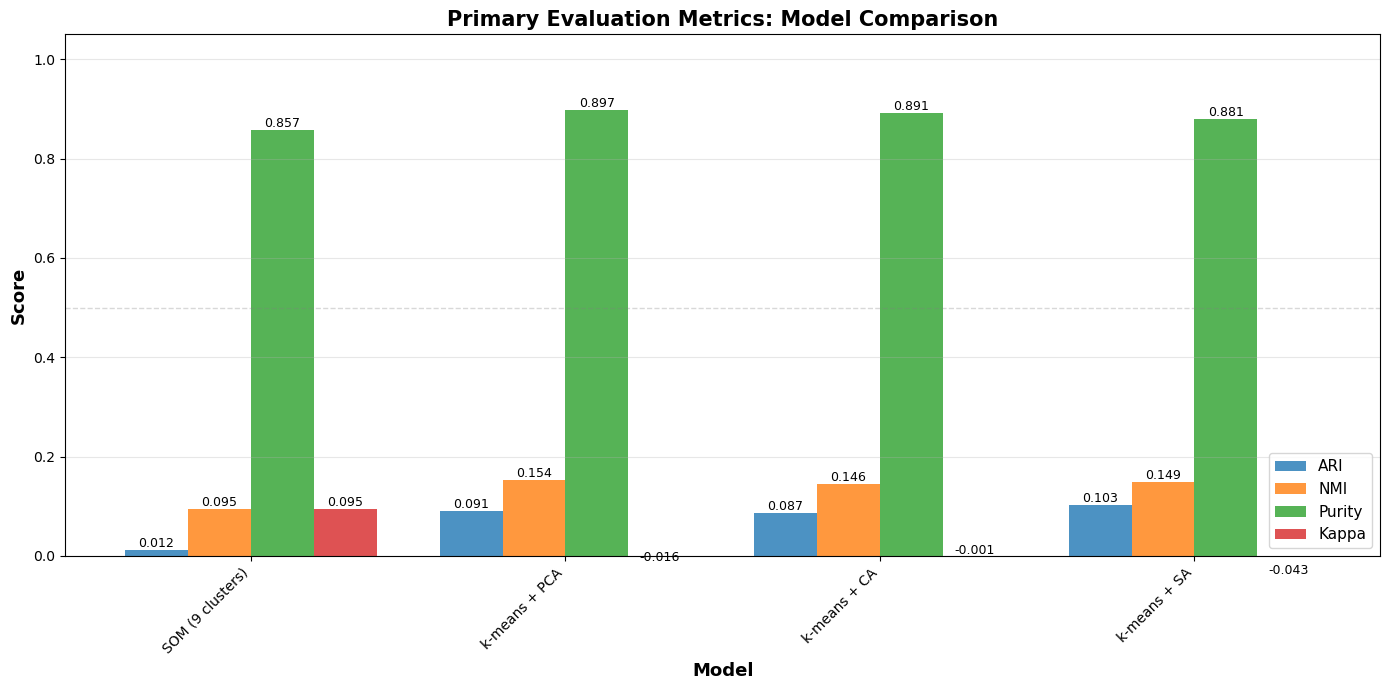

Saved: ./Figures/model_comparison_primary_metrics.png


In [6]:
# VISUALIZATION 1: PRIMARY METRICS COMPARISON
# Plot primary metrics: ARI, NMI, Purity, Kappa
fig, ax = plt.subplots(figsize=(14, 7))
metrics_df = pd.DataFrame(results).T

# Select primary metrics for main plot
primary_metrics = ['ARI', 'NMI', 'Purity', 'Kappa']
metrics_to_plot = metrics_df[primary_metrics]

# Plot grouped bar chart
x = np.arange(len(metrics_to_plot))
width = 0.2

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for i, metric in enumerate(primary_metrics):
    offset = width * (i - 1.5)
    bars = ax.bar(x + offset, metrics_to_plot[metric], width, 
                   label=metric, color=colors[i], alpha=0.8)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        if not np.isnan(height):
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.3f}',
                   ha='center', va='bottom', fontsize=9)

ax.set_ylabel('Score', fontsize=13, fontweight='bold')
ax.set_xlabel('Model', fontsize=13, fontweight='bold')
ax.set_title('Primary Evaluation Metrics: Model Comparison', 
             fontsize=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot.index, rotation=45, ha='right')
ax.legend(fontsize=11, loc='lower right')
ax.set_ylim([0, 1.05])
ax.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, alpha=0.3, label='0.5 baseline')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('./Figures/model_comparison_primary_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved: ./Figures/model_comparison_primary_metrics.png")

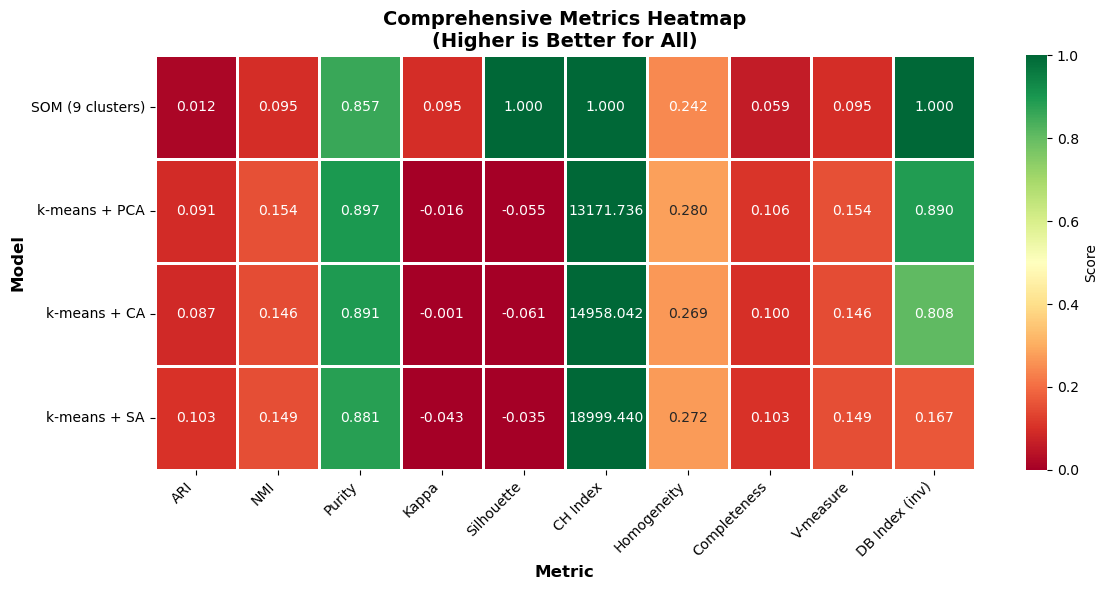

Saved: ./Figures/model_comparison_heatmap.png


In [7]:
# VISUALIZATION 1B: ALL METRICS HEATMAP
fig, ax = plt.subplots(figsize=(12, 6))

# Create heatmap - but handle DB Index specially (lower is better)
metrics_df_display = metrics_df.copy()

# Invert DB Index for display (so higher = better for all metrics in heatmap)
if 'DB Index' in metrics_df_display.columns:
    # Normalize DB to 0-1 scale and invert
    db_values = metrics_df_display['DB Index'].values
    if not np.all(np.isnan(db_values)):
        db_max = np.nanmax(db_values)
        if db_max > 0:
            metrics_df_display['DB Index (inv)'] = 1 - (db_values / (db_max * 1.2))
            metrics_df_display = metrics_df_display.drop('DB Index', axis=1)

sns.heatmap(metrics_df_display, annot=True, fmt='.3f', cmap='RdYlGn', 
            vmin=0, vmax=1, center=0.5,
            cbar_kws={'label': 'Score'}, ax=ax,
            linewidths=1, linecolor='white')

ax.set_title('Comprehensive Metrics Heatmap\n(Higher is Better for All)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Metric', fontsize=12, fontweight='bold')
ax.set_ylabel('Model', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('./Figures/model_comparison_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved: ./Figures/model_comparison_heatmap.png")

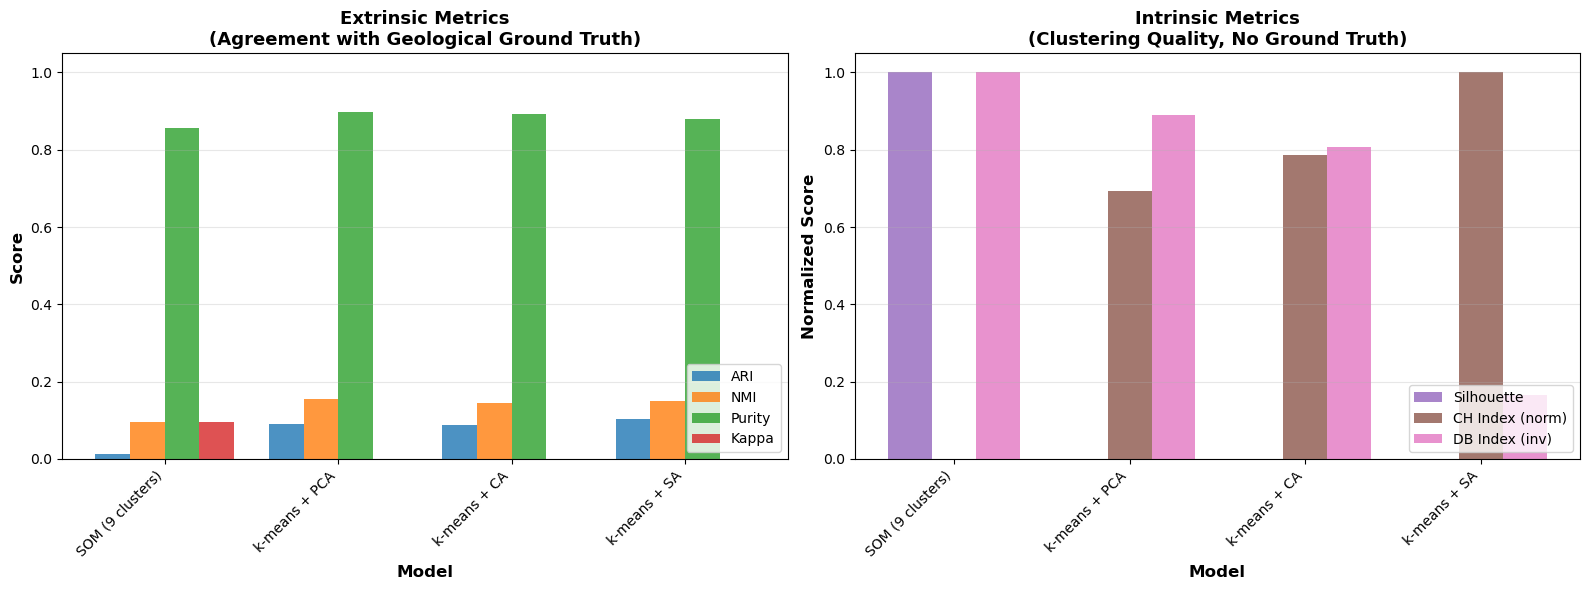

Saved: ./Figures/model_comparison_intrinsic_vs_extrinsic.png


In [8]:
# VISUALIZATION 1C: INTRINSIC VS EXTRINSIC METRICS

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Extrinsic metrics (with ground truth)
extrinsic = ['ARI', 'NMI', 'Purity', 'Kappa']
extrinsic_df = metrics_df[extrinsic]

x = np.arange(len(extrinsic_df))
width = 0.2
colors_extrinsic = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, metric in enumerate(extrinsic):
    offset = width * (i - 1.5)
    bars = ax1.bar(x + offset, extrinsic_df[metric], width,
                   label=metric, color=colors_extrinsic[i], alpha=0.8)

ax1.set_ylabel('Score', fontsize=12, fontweight='bold')
ax1.set_xlabel('Model', fontsize=12, fontweight='bold')
ax1.set_title('Extrinsic Metrics\n(Agreement with Geological Ground Truth)',
              fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(extrinsic_df.index, rotation=45, ha='right')
ax1.legend(fontsize=10, loc='lower right')
ax1.set_ylim([0, 1.05])
ax1.grid(axis='y', alpha=0.3)

# Intrinsic metrics (clustering quality)
intrinsic = ['Silhouette', 'CH Index', 'DB Index']
# Check which intrinsic metrics are available
available_intrinsic = [m for m in intrinsic if m in metrics_df.columns]

if available_intrinsic:
    intrinsic_df = metrics_df[available_intrinsic].copy()
    
    # Normalize CH Index to 0-1 for visualization
    if 'CH Index' in intrinsic_df.columns:
        ch_values = intrinsic_df['CH Index'].values
        if not np.all(np.isnan(ch_values)):
            ch_min, ch_max = np.nanmin(ch_values), np.nanmax(ch_values)
            if ch_max > ch_min:
                intrinsic_df['CH Index (norm)'] = (ch_values - ch_min) / (ch_max - ch_min)
                intrinsic_df = intrinsic_df.drop('CH Index', axis=1)
    
    # Invert DB Index (lower is better → higher is better for display)
    if 'DB Index' in intrinsic_df.columns:
        db_values = intrinsic_df['DB Index'].values
        if not np.all(np.isnan(db_values)):
            db_max = np.nanmax(db_values)
            if db_max > 0:
                intrinsic_df['DB Index (inv)'] = 1 - (db_values / (db_max * 1.2))
                intrinsic_df = intrinsic_df.drop('DB Index', axis=1)
    
    x2 = np.arange(len(intrinsic_df))
    width2 = 0.25
    colors_intrinsic = ['#9467bd', '#8c564b', '#e377c2']
    
    for i, metric in enumerate(intrinsic_df.columns):
        offset = width2 * (i - 1)
        bars = ax2.bar(x2 + offset, intrinsic_df[metric], width2,
                      label=metric, color=colors_intrinsic[i % len(colors_intrinsic)], alpha=0.8)
    
    ax2.set_ylabel('Normalized Score', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Model', fontsize=12, fontweight='bold')
    ax2.set_title('Intrinsic Metrics\n(Clustering Quality, No Ground Truth)',
                  fontsize=13, fontweight='bold')
    ax2.set_xticks(x2)
    ax2.set_xticklabels(intrinsic_df.index, rotation=45, ha='right')
    ax2.legend(fontsize=10, loc='lower right')
    ax2.set_ylim([0, 1.05])
    ax2.grid(axis='y', alpha=0.3)
else:
    ax2.text(0.5, 0.5, 'Intrinsic metrics not available\n(requires encoded data)',
             ha='center', va='center', fontsize=12, transform=ax2.transAxes)
    ax2.set_xticks([])
    ax2.set_yticks([])

plt.tight_layout()
plt.savefig('./Figures/model_comparison_intrinsic_vs_extrinsic.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved: ./Figures/model_comparison_intrinsic_vs_extrinsic.png")


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_25808/4179530244.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab10', n_clusters)


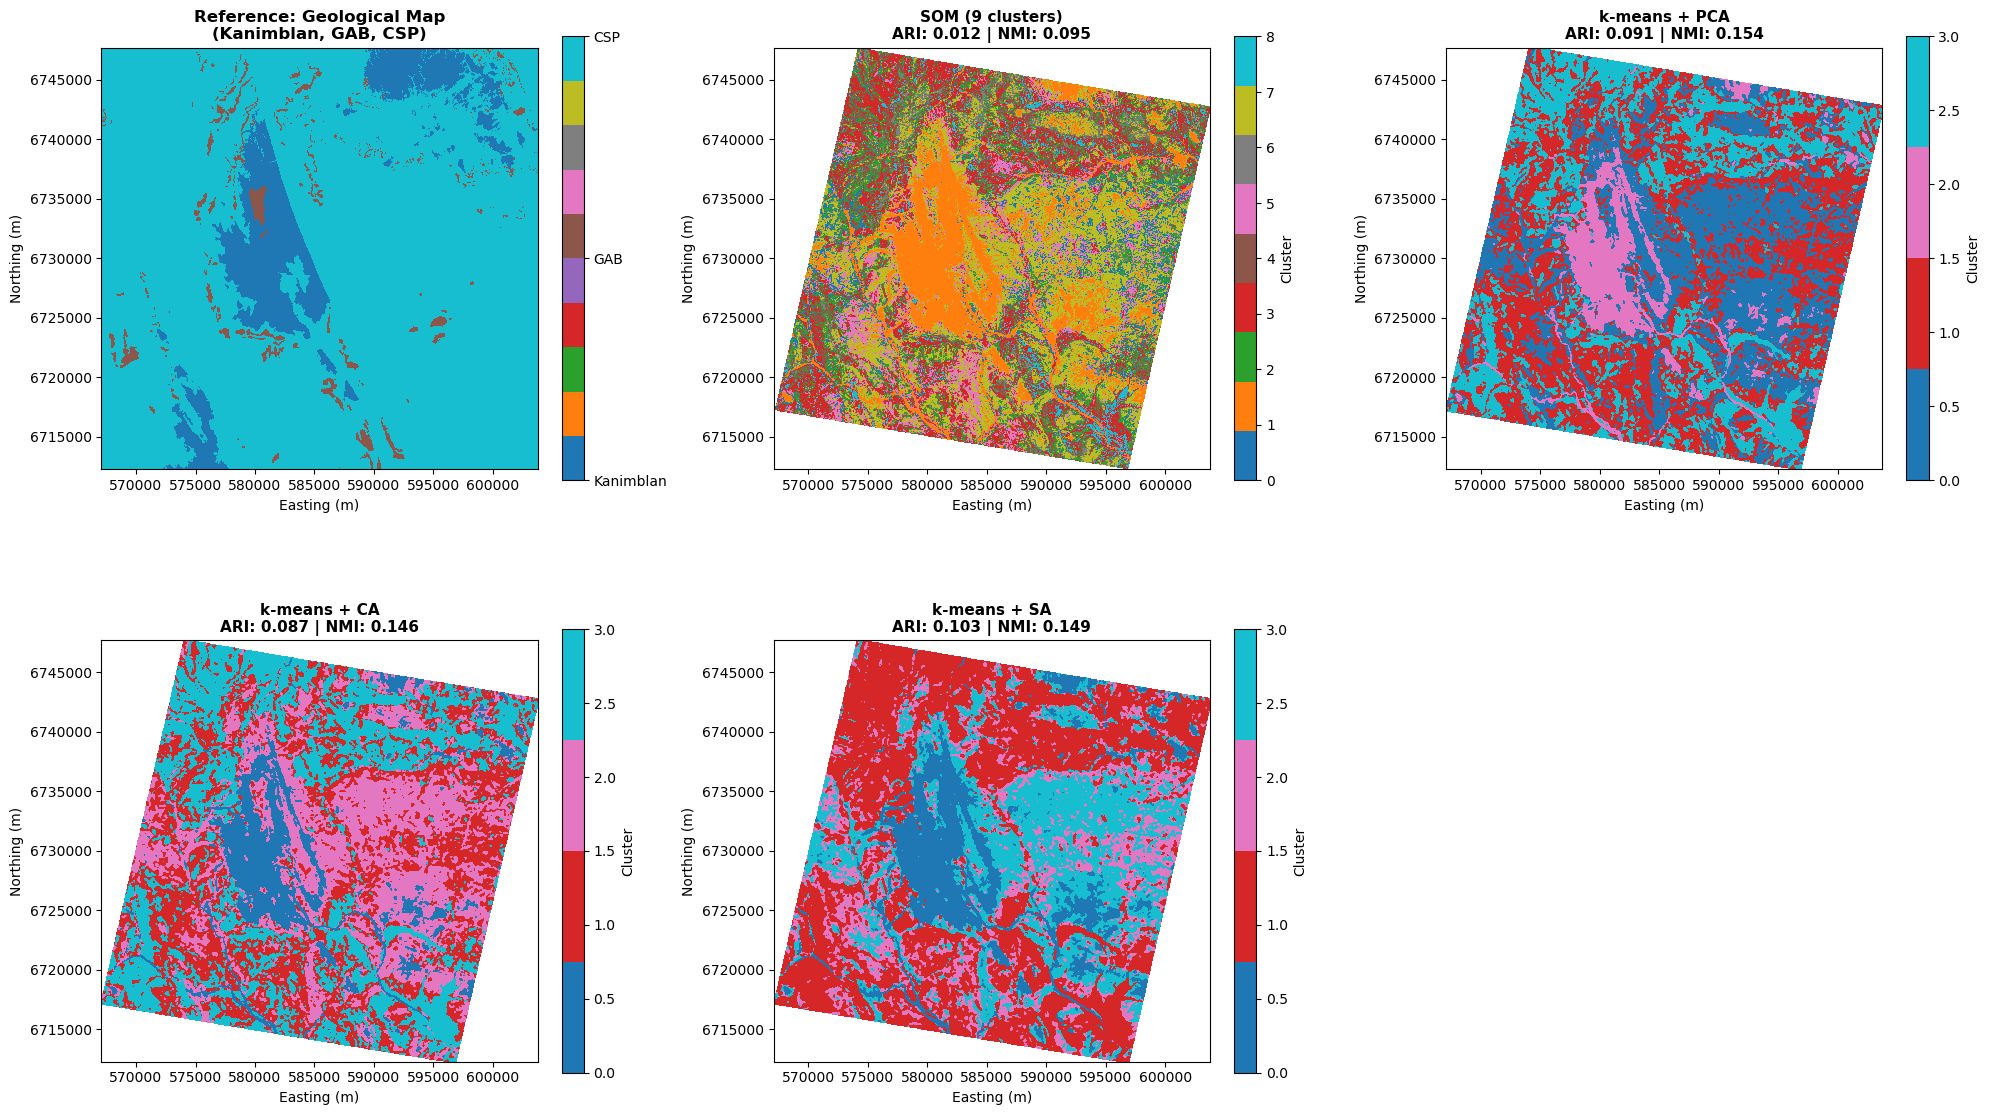

Saved: ./Figures/model_comparison_maps.png


In [9]:
# VISUALIZATION 2: SIDE-BY-SIDE MAPS
n_models = len(models)
n_cols = 3
n_rows = (n_models + 2) // n_cols  # +1 for reference, round up

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6*n_rows))
axes = axes.flatten() if n_models > 1 else [axes]

# Reference map
ax = axes[0]
im = ax.imshow(geology_ref.values, extent=extent, cmap='tab10', 
               interpolation='nearest', vmin=1, vmax=3)
ax.set_title('Reference: Geological Map\n(Kanimblan, GAB, CSP)', 
             fontsize=12, fontweight='bold')
ax.set_xlabel('Easting (m)', fontsize=10)
ax.set_ylabel('Northing (m)', fontsize=10)
ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
cbar = plt.colorbar(im, ax=ax, ticks=[1, 2, 3], fraction=0.046)
cbar.set_ticklabels(['Kanimblan', 'GAB', 'CSP'])

# Model maps
for idx, (model_name, pred_labels_spatial) in enumerate(models.items(), start=1):
    ax = axes[idx]
    
    n_clusters = len(np.unique(pred_labels_spatial[~np.isnan(pred_labels_spatial)]))
    cmap = plt.cm.get_cmap('tab10', n_clusters)
    cmap.set_bad(color='white')
    
    im = ax.imshow(pred_labels_spatial, extent=extent, cmap=cmap, 
                   interpolation='nearest')
    
    # Get metrics for title
    ari = results[model_name]['ARI']
    nmi = results[model_name]['NMI']
    
    ax.set_title(f'{model_name}\nARI: {ari:.3f} | NMI: {nmi:.3f}', 
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Easting (m)', fontsize=10)
    ax.set_ylabel('Northing (m)', fontsize=10)
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    plt.colorbar(im, ax=ax, label='Cluster', fraction=0.046)

# Hide extra subplots
for idx in range(n_models + 1, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig('./Figures/model_comparison_maps.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved: ./Figures/model_comparison_maps.png")

/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_25808/2124625062.py:23: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_25808/2124625062.py:23: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_25808/2124625062.py:23: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_25808/2124625062.py:23: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


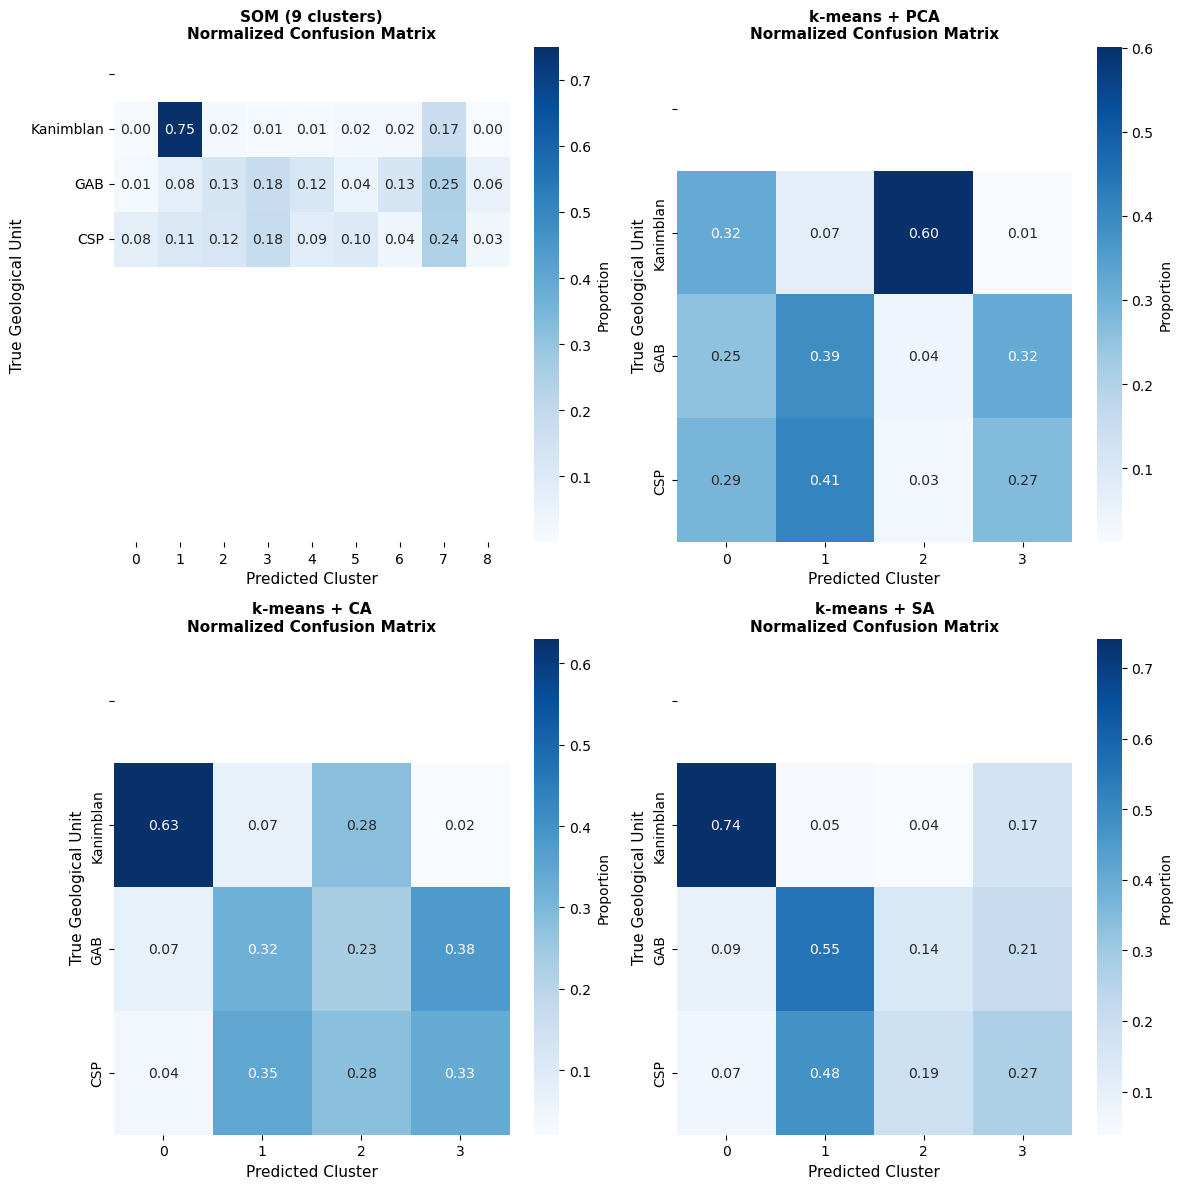

Saved: ./Figures/confusion_matrices.png


In [19]:
# VISUALIZATION 3: CONFUSION MATRICES
if len(models) > 0:
    n_models = len(models)
    n_cols = 2
    n_rows = (n_models + 1) // 2
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 6*n_rows))
    if n_models == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for idx, (model_name, pred_labels_spatial) in enumerate(models.items()):
        pred_labels = pred_labels_spatial.flatten()
        valid_mask = ~np.isnan(pred_labels)
        ref_valid = ref_labels[valid_mask].astype(int)
        pred_valid = pred_labels[valid_mask].astype(int)
        
        # Compute confusion matrix
        cm = confusion_matrix(ref_valid, pred_valid)
        
        # Normalize by true class (rows)
        cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        
        # Plot
        ax = axes[idx]
        sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', ax=ax,
                    cbar_kws={'label': 'Proportion'},
                    xticklabels=sorted(np.unique(pred_valid)),
                    yticklabels=['','Kanimblan', 'GAB', 'CSP'])
        ax.set_title(f'{model_name}\nNormalized Confusion Matrix', 
                     fontweight='bold', fontsize=11)
        ax.set_xlabel('Predicted Cluster', fontsize=11)
        ax.set_ylabel('True Geological Unit', fontsize=11)
    
    # Hide extra subplots
    for idx in range(len(models), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.savefig('./Figures/confusion_matrices.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Saved: ./Figures/confusion_matrices.png")

In [23]:
# SUMMARY TABLE
metrics_df = pd.DataFrame(results).T
metrics_df = metrics_df.round(4)

print("\n" + metrics_df.to_string())

# Save to CSV
metrics_df.to_csv('./Figures/model_comparison_results.csv')
print("\n✓ Saved: ./Figures/model_comparison_results.csv")


                     ARI     NMI  Purity   Kappa  Silhouette    CH Index  DB Index  Homogeneity  Completeness  V-measure
SOM (9 clusters)  0.0118  0.0945  0.8567  0.0949      1.0000      1.0000    0.0000       0.2424        0.0587     0.0945
k-means + PCA     0.0910  0.1539  0.8968 -0.0158     -0.0615  13171.7357   15.1055       0.2802        0.1061     0.1539
k-means + CA      0.0866  0.1457  0.8914 -0.0014     -0.0605  14958.0421   26.3674       0.2692        0.0999     0.1457
k-means + SA      0.1031  0.1494  0.8805 -0.0433     -0.0416  18999.4397  114.2558       0.2716        0.1031     0.1494

✓ Saved: ./Figures/model_comparison_results.csv


In [24]:
# INTERPRETATION GUIDE
print("""
PRIMARY METRICS:
================

Adjusted Rand Index (ARI): [-1 to 1]
  • Measures similarity between clustering and ground truth
  • 1.0 = perfect match with geology
  • 0.0 = random clustering
  • ↑ Higher is better
  • Expectation: SOM typically ≥ k-means

Normalized Mutual Information (NMI): [0 to 1]
  • Measures information shared between clustering and ground truth
  • 1.0 = perfect correspondence
  • 0.0 = independent clusterings
  • ↑ Higher is better
  • Expectation: SOM usually gives smoother results

Purity: [0 to 1]
  • Percentage of correctly assigned samples in dominant class per cluster
  • 1.0 = each cluster contains only one geological unit
  • > 0.7 is considered good
  • ↑ Higher is better

Cohen's Kappa (κ): [-1 to 1]
  • Agreement between clustering and geology, correcting for chance
  • 1.0 = perfect agreement
  • 0.0 = agreement by chance
  • ↑ Higher is better
  • Interpretation:
    - 0.81-1.00: Almost perfect agreement
    - 0.61-0.80: Substantial agreement
    - 0.41-0.60: Moderate agreement
    - 0.21-0.40: Fair agreement
    - 0.00-0.20: Slight agreement

Silhouette Score: [-1 to 1]
  • Measures how well-separated and compact clusters are
  • 1.0 = perfectly separated clusters
  • 0.0 = overlapping clusters
  • -1.0 = mis-assigned samples
  • ↑ Higher is better
  • Requires encoded data from dimensionality reduction

Calinski-Harabasz Index (CH): [0 to ∞]
  • Ratio of between-cluster to within-cluster dispersion
  • Also called Variance Ratio Criterion
  • Higher values = better defined, more separated clusters
  • ↑ Higher is better
  • Interpretation:
    - No fixed threshold
    - Compare across methods (higher is better)
    - Useful for determining optimal number of clusters
  • Advantage: Fast to compute, no ground truth needed

Davies-Bouldin Index (DB): [0 to ∞]
  • Average similarity ratio of each cluster with its most similar cluster
  • Measures cluster overlap/separation
  • 0 = perfect separation (lower bound)
  • ↓ Lower is better
  • Interpretation:
    - < 1.0: Well-separated clusters
    - 1.0-2.0: Moderate separation
    - > 2.0: Poorly separated clusters
  • Advantage: Intuitive interpretation, no ground truth needed

SUPPORTING METRICS:
==================

Homogeneity: [0 to 1]
  • Each cluster contains only members of a single class
  • 1.0 = pure clusters
  • ↑ Higher is better

Completeness: [0 to 1]
  • All members of a given class are assigned to same cluster
  • 1.0 = classes fully captured
  • ↑ Higher is better

V-measure: [0 to 1]
  • Harmonic mean of homogeneity and completeness
  • Balances both properties
  • ↑ Higher is better

VISUAL ASSESSMENT:
==================
  • Spatial coherence: Do clusters follow geological boundaries?
  • Smoothness: Are there excessive speckled/noisy classifications?
  • Geological interpretation: Do clusters make geological sense?
""")


PRIMARY METRICS:

Adjusted Rand Index (ARI): [-1 to 1]
  • Measures similarity between clustering and ground truth
  • 1.0 = perfect match with geology
  • 0.0 = random clustering
  • ↑ Higher is better
  • Expectation: SOM typically ≥ k-means

Normalized Mutual Information (NMI): [0 to 1]
  • Measures information shared between clustering and ground truth
  • 1.0 = perfect correspondence
  • 0.0 = independent clusterings
  • ↑ Higher is better
  • Expectation: SOM usually gives smoother results

Purity: [0 to 1]
  • Percentage of correctly assigned samples in dominant class per cluster
  • 1.0 = each cluster contains only one geological unit
  • > 0.7 is considered good
  • ↑ Higher is better

Cohen's Kappa (κ): [-1 to 1]
  • Agreement between clustering and geology, correcting for chance
  • 1.0 = perfect agreement
  • 0.0 = agreement by chance
  • ↑ Higher is better
  • Interpretation:
    - 0.81-1.00: Almost perfect agreement
    - 0.61-0.80: Substantial agreement
    - 0.41-0.60: